# QMSS5074GR: Projects in Advanced Machine Learning
## Project 2: CNN & Transfer Learning for Medical Image Classification

---

### Group Information

Fill this in before you submit.

**Group number:** 7

| Full Name | UNI |
|-----------|-----|
|     Benjamin Robinson-Rosendorff      |   br2844  |
|      Isha Malaviya              | im2650|

**Public GitHub repository URL:** https://github.com/benjyrr/ML-Fall-26-Project_2

## How to Complete and Submit This Project

**Due: Monday, November 16, 2026**

This notebook is the whole assignment. Everything you need to do is written here, and the completed notebook is the only thing you submit. Keep the file name `Project_2.ipynb`.

### 1. Get started

This project runs in **Google Colab**, which gives you a free GPU for training. The project folder contains the notebook:

```
Fall2026_QMSS5074GR_Project_2/
└── Project_2.ipynb
```

The dataset is too large to include in the folder, so it is shared through Google Drive (step 3 below). There is nothing else to download.

1. Unzip the project folder. Then go to [colab.research.google.com](https://colab.research.google.com), sign in with your **Columbia (LionMail) Google account**, choose **File → Upload notebook**, and select `Project_2.ipynb`.
2. Check that a GPU is on: **Runtime → Change runtime type → T4 GPU**.
3. Add the dataset to your Google Drive (you only need to do this once):
   1. Open the [shared dataset folder](https://drive.google.com/drive/folders/18O-BnGOIw9ZiUwy17Uk_361xyfTF-qAN?usp=sharing) while signed in with your Columbia account.
   2. Right-click **`COVID-19_Radiography_Dataset.zip`** and choose **Organize → Add shortcut**.
   3. Choose **All locations → My Drive → Add**.

   ![Step 1: Right-click the zip file, then Organize, then Add shortcut](https://github.com/user-attachments/assets/6515aa71-484b-4364-ac44-2331477720e8)

   ![Step 2: Choose All locations, then My Drive, then Add](https://github.com/user-attachments/assets/0d0d8f6c-a868-49c4-9e38-54f3006af39b)

4. Run the cells in **Section 0** in order. They connect to your Drive, unzip the dataset, and prepare the data you will use for every model.

**Working in Colab:**

- Colab saves your notebook in your Google Drive, in the **Colab Notebooks** folder.
- If your session disconnects, the unzipped data and trained models are lost. Run Section 0 again to continue.
- If you run out of memory, delete models you no longer need with `del model_name` and `tf.keras.backend.clear_session()`, or use the optional save and reload cells at the end of Section 0.

### 2. Complete the notebook

- Every **`TODO`** marks something you must do: write code, choose parameters, or answer a question.
- Write your answers in the cells marked *Replace this section with your response.*
- Remove each `TODO` marker once you have completed it. Any `TODO` left at submission counts as **incomplete**.
- You may add extra cells for additional experiments.

### 3. Before you submit

- Run **Runtime → Restart session and run all**. The notebook must run from top to bottom without errors, with all outputs (tables, plots, scores) visible. Training several models takes time, so leave enough time for this final run.
- Fill in the **Group Information** cell at the top, including your GitHub link.
- Download the notebook with **File → Download → Download .ipynb**.

### 4. Submit in two places

| Where | What to submit |
|-------|----------------|
| **Canvas** (Project 2 assignment) | This completed `.ipynb` file. **One member submits for the whole group.** |
| **GitHub** (your group's public repository) | The same `.ipynb`, inside a `Project_2` folder |

Your repository should look like this:

```
<your-group-repo>/
└── Project_2/
    └── Project_2.ipynb
```

Do **not** upload the dataset, saved data files, or saved models to GitHub. They are too large (GitHub rejects files over 100 MB).

The repository must be **public**. To check, open your link in a private/incognito browser window.

### Submission checklist

- [ ] Group number, names, UNIs, and GitHub link are filled in at the top
- [ ] No `TODO` is left anywhere in the notebook
- [ ] Restart session and run all finishes with no errors, and all outputs are visible
- [ ] One group member has submitted the `.ipynb` to Canvas
- [ ] The same `.ipynb` is in `Project_2/` in your public group repository

## About the Project

### What this project is about

Chest X-rays are one of the fastest and cheapest ways to examine the lungs, and they were widely used to screen patients during the COVID-19 pandemic. Reading them takes trained radiologists, who are often in short supply. Can a deep learning model learn to tell COVID-19, viral pneumonia, and healthy lungs apart from an X-ray image?

In this project, you will build a complete deep learning pipeline for **medical image classification**. You will train a convolutional neural network (CNN) from scratch as a baseline, apply **transfer learning** with ResNet, try three more architectures of your choice, test data augmentation, and compare every model on the same test set. Finally, you will reflect on which model works best, why, and how it could be useful in the real world.

> The models in this project are for learning purposes only. They are not suitable for diagnosing patients.

### The prediction task

This is a **multi-class image classification** problem with **three classes**:

**COVID-19 · Normal · Viral Pneumonia**

Each model takes a chest X-ray image as input and outputs the probability of each class.

### The data

The images come from the **COVID-19 Radiography Database**, created by researchers from Qatar University, the University of Dhaka, and their collaborators. It collects chest X-rays from several public sources into one dataset.

> **Citation:** M.E.H. Chowdhury, T. Rahman, A. Khandakar, R. Mazhar, M.A. Kadir, Z.B. Mahbub, K.R. Islam, M.S. Khan, A. Iqbal, N. Al-Emadi, M.B.I. Reaz, "Can AI help in screening Viral and COVID-19 pneumonia?" arXiv preprint, 29 March 2020. [https://arxiv.org/abs/2003.13145](https://arxiv.org/abs/2003.13145)

The dataset is organized into one folder per class. This project uses three of them:

| Class | Folder | Images in the dataset | Images used in this project |
|-------|--------|----------------------:|----------------------------:|
| COVID-19 | `COVID/images` | 3,616 | 1,345 |
| Normal | `Normal/images` | 10,192 | 1,345 |
| Viral Pneumonia | `Viral Pneumonia/images` | 1,345 | 1,345 |

The dataset also contains a fourth class (`Lung_Opacity`) and lung masks for each image (`masks` folders). This project does not use them.

### How the data is prepared

Section 0 prepares the data for you, so that every model uses exactly the same inputs:

- **Equal-sized classes:** A random sample of 1,345 images is taken from each class, the size of the smallest class. This keeps the data small enough for Colab's memory, and it also balances the classes. You will discuss this choice in Section 1.
- **Image format:** Each image is resized to **192 × 192** pixels, stored with **3 color channels** (so that pre-trained models such as ResNet can use it), and scaled to values between **0 and 1**.
- **Fixed split:** The data is split into **training (64%)**, **validation (16%)**, and **test (20%)** sets, with the same class proportions in each. Use these same splits for every model so that your comparisons are fair.

---

## 0. Setup and Data Loading

Run these cells in order. This code is provided, so you don't need to change it. When you finish this section, you will have `X_train`, `X_val`, `X_test` (images) and `y_train`, `y_val`, `y_test` (one-hot encoded labels).

### Connect to Google Drive

In [2]:
# Connect to Google Drive. A pop-up will ask you to sign in: use your Columbia account.
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### Unzip the Dataset

In [3]:
# Unzip the dataset into this Colab session (takes 1–2 minutes; skipped if it is already unzipped)
import os
import glob
import zipfile

drive_folder = '/content/drive/MyDrive'
zip_path = os.path.join(drive_folder, 'COVID-19_Radiography_Dataset.zip')

if not os.path.exists(zip_path):
    # Also look one folder down, in case the shortcut was added inside a folder
    matches = glob.glob(os.path.join(drive_folder, '*', 'COVID-19_Radiography_Dataset.zip'))
    if not matches:
        raise FileNotFoundError(
            "Couldn't find COVID-19_Radiography_Dataset.zip in your Google Drive. "
            "Follow step 3 of 'How to Complete and Submit This Project' to add the shortcut to My Drive.")
    zip_path = matches[0]

if not os.path.isdir('COVID-19_Radiography_Dataset'):
    with zipfile.ZipFile(zip_path) as z:
        z.extractall('.')

print('Dataset ready:', sorted(os.listdir('COVID-19_Radiography_Dataset')))

Dataset ready: ['COVID', 'COVID.metadata.xlsx', 'Lung_Opacity', 'Lung_Opacity.metadata.xlsx', 'Normal', 'Normal.metadata.xlsx', 'README.md.txt', 'Viral Pneumonia', 'Viral Pneumonia.metadata.xlsx']


### Import Libraries

In [4]:
import os
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import (Input, Conv2D, MaxPooling2D, Dense, Dropout, Flatten,
                                     BatchNormalization, GlobalAveragePooling2D)
from tensorflow.keras.optimizers import Adam, SGD, RMSprop
from tensorflow.keras.applications import ResNet50, VGG19, InceptionV3

# Fix random seeds so results are as repeatable as possible
keras.utils.set_random_seed(42)

print('TensorFlow version:', tf.__version__)
print('GPU:', tf.config.list_physical_devices('GPU') or 'None found. Turn it on with Runtime → Change runtime type → T4 GPU.')

TensorFlow version: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### Collect Image File Paths

In [5]:
base_path = 'COVID-19_Radiography_Dataset'
categories = ['COVID/images', 'Normal/images', 'Viral Pneumonia/images']
class_names = ['COVID', 'NORMAL', 'PNEUMONIA']

# One list of file paths per class
fnames = []
for category in categories:
    image_folder = os.path.join(base_path, category)
    file_names = sorted(os.listdir(image_folder))
    fnames.append([os.path.join(image_folder, f) for f in file_names])

# Keep the full counts: you will need them in Section 1
original_counts = dict(zip(class_names, [len(f) for f in fnames]))
print('Number of images in each class (full dataset):', original_counts)

Number of images in each class (full dataset): {'COVID': 3616, 'NORMAL': 10192, 'PNEUMONIA': 1345}


### Sample an Equal Number of Images per Class

In [6]:
# Take a random sample from each class, the size of the smallest class.
# This keeps the data small enough for Colab's memory and balances the classes.
n_per_class = min(len(f) for f in fnames)

rng = random.Random(42)
fnames = [sorted(rng.sample(f, n_per_class)) for f in fnames]

print('Images per class used in this project:', n_per_class)

Images per class used in this project: 1345


### Preprocess the Images

In [7]:
IMG_SIZE = 192

def preprocessor(img_path):
    """Load one image, convert it to 3-channel RGB, resize it, and scale pixel values to 0–1."""
    img = Image.open(img_path).convert('RGB').resize((IMG_SIZE, IMG_SIZE))
    return np.asarray(img, dtype=np.float32) / 255.0

# Try it on one image
preprocessor(fnames[0][0]).shape

(192, 192, 3)

In [8]:
# Load and preprocess every image (takes about a minute)
image_filepaths = fnames[0] + fnames[1] + fnames[2]

X = np.empty((len(image_filepaths), IMG_SIZE, IMG_SIZE, 3), dtype=np.float32)
for i, path in enumerate(image_filepaths):
    X[i] = preprocessor(path)

print('X shape:', X.shape)          # (number of images, height, width, channels)
print('Pixel range:', X.min(), 'to', X.max())

X shape: (4035, 192, 192, 3)
Pixel range: 0.0 to 1.0


### Create the Labels

In [9]:
# The images were loaded class by class, so the labels follow the same order
y_labels = np.repeat(class_names, n_per_class)

# One-hot encode the labels for Keras (one column per class)
y = pd.get_dummies(y_labels).astype('float32')
y

,COVID,NORMAL,PNEUMONIA
0,1.0,0.0,0.0
1,1.0,0.0,0.0
2,1.0,0.0,0.0
3,1.0,0.0,0.0
4,1.0,0.0,0.0
...,...,...,...
4030,0.0,0.0,1.0
4031,0.0,0.0,1.0
4032,0.0,0.0,1.0
4033,0.0,0.0,1.0


### Look at Sample Images

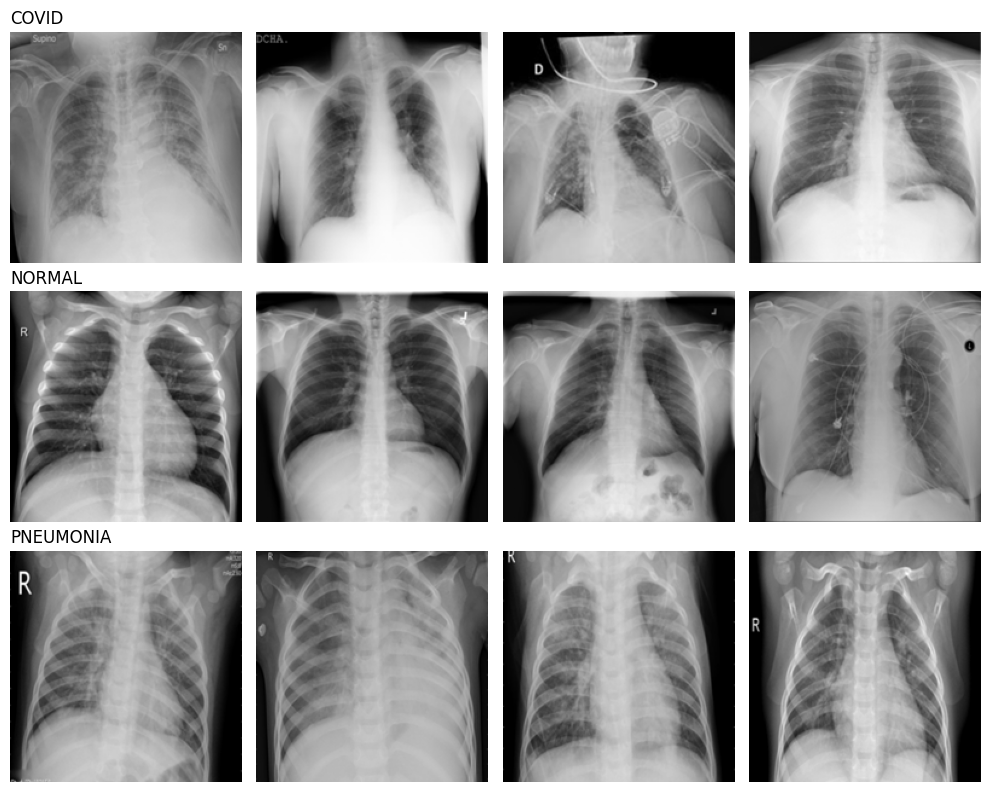

In [10]:
fig, axes = plt.subplots(3, 4, figsize=(10, 8))
for row, (name, files) in enumerate(zip(class_names, fnames)):
    for col in range(4):
        ax = axes[row, col]
        ax.imshow(preprocessor(files[col]))
        ax.axis('off')
        if col == 0:
            ax.set_title(name, loc='left')
plt.tight_layout()
plt.show()

### Split into Training, Validation, and Test Sets

In [11]:
# 20% test set, then 20% of the remaining data as a validation set (64% / 16% / 20% overall)
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
del X  # free memory

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.2, stratify=y_train_full, random_state=42)
del X_train_full, y_train_full  # free memory

print('Training:  ', X_train.shape, y_train.shape)
print('Validation:', X_val.shape, y_val.shape)
print('Test:      ', X_test.shape, y_test.shape)

Training:   (2582, 192, 192, 3) (2582, 3)
Validation: (646, 192, 192, 3) (646, 3)
Test:       (807, 192, 192, 3) (807, 3)


### Optional: Save and Reload the Prepared Data

If Colab runs out of memory, use **Runtime → Restart session** and run the reload cell below instead of all of Section 0 (run the **Import Libraries** cell first). The saved files are stored in this Colab session only, so they are lost if the session disconnects.

In [12]:
# Save the prepared data (optional)
for name, arr in [('X_train', X_train), ('X_val', X_val), ('X_test', X_test),
                  ('y_train', y_train), ('y_val', y_val), ('y_test', y_test)]:
    np.save(f'{name}.npy', np.asarray(arr))

In [13]:
# Reload the prepared data (optional)
X_train, X_val, X_test = (np.load(f'{name}.npy') for name in ['X_train', 'X_val', 'X_test'])
y_train, y_val, y_test = (pd.DataFrame(np.load(f'{name}.npy'), columns=class_names)
                          for name in ['y_train', 'y_val', 'y_test'])

---

## 1. Dataset and Exploratory Data Analysis

### Describe the Dataset

Describe the dataset using basic statistics and sample images. For example, show the number of images per class in each split, the image dimensions, pixel intensity statistics, and several sample images from each class.

Train {'COVID': 860, 'NORMAL': 861, 'PNEUMONIA': 861}
Validation {'COVID': 216, 'NORMAL': 215, 'PNEUMONIA': 215}
Test {'COVID': 269, 'NORMAL': 269, 'PNEUMONIA': 269}
Image dimensions: (192, 192, 3)
Min pixel: 0.0
Max pixel: 1.0
Mean pixel: 0.5131396
Std pixel: 0.2509583


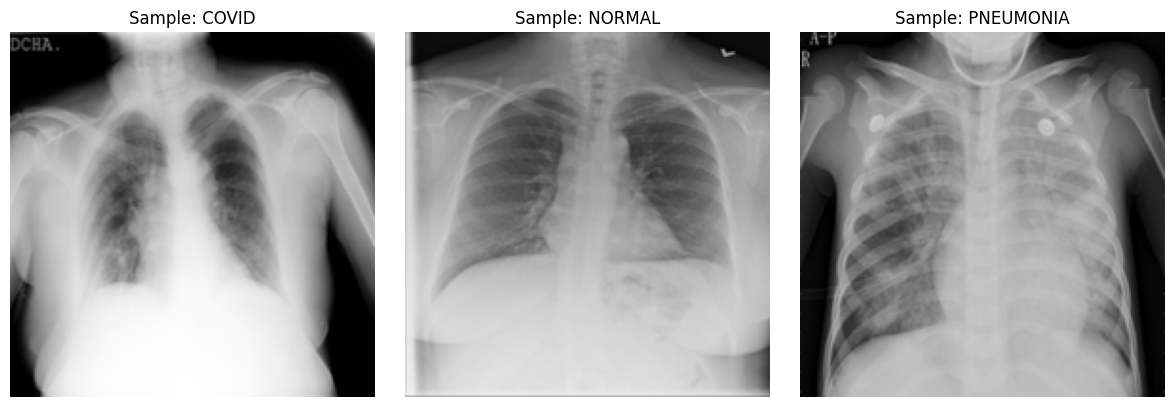

In [14]:
# Number of images per class in each split
for name, images, labels in [
    ("Train", X_train, y_train),
    ("Validation", X_val, y_val),
    ("Test", X_test, y_test)
]:
    print(name, labels.sum().astype(int).to_dict())

# Image dimensions and pixel statistics
print("Image dimensions:", X_train.shape[1:])
print("Min pixel:", X_train.min())
print("Max pixel:", X_train.max())
print("Mean pixel:", X_train.mean())
print("Std pixel:", X_train.std())

# Sample images from each class
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for i, class_name in enumerate(class_names):
    # Find the index of the first image belonging to this class in the training set
    class_idx = np.argmax(y_train[class_name] == 1)

    axes[i].imshow(X_train[class_idx])
    axes[i].set_title(f"Sample: {class_name}")
    axes[i].axis('off')

plt.tight_layout()
plt.show()

Describe what you observe. How do the three classes look different, and how might that help or challenge a model?

The dataset contains three classes: COVID, Normal, and Viral Pneumonia. All images are resized to 192 × 192 pixels, with pixel values scaled between 0 and 1.

Normal X-rays generally show clearer lungs, while COVID and pneumonia X-rays may show cloudy or white areas caused by lung inflammation. COVID and viral pneumonia can look similar, making them harder for the model to distinguish.

A CNN may learn these visual patterns, but similarities between diseases and differences in image quality could make classification challenging.

### Class Balance

The full dataset is **imbalanced**, but Section 0 uses the same number of images from each class. Using `original_counts`, plot the number of images per class in the full dataset next to the number used in this project.

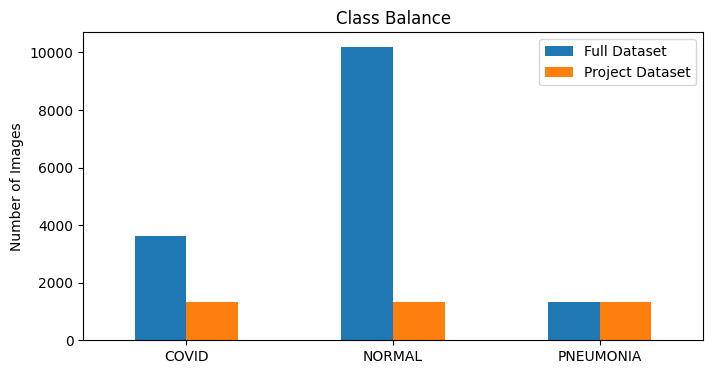

In [15]:
counts = pd.DataFrame({
    "Full Dataset": original_counts,
    "Project Dataset": {c: n_per_class for c in class_names}
})

counts.plot(kind="bar", figsize=(8, 4))
plt.ylabel("Number of Images")
plt.title("Class Balance")
plt.xticks(rotation=0)
plt.show()

Answer the following:

1. How imbalanced is the full dataset? <br><br>
The full dataset is imbalanced, with 10,192 Normal, 3,616 COVID, and 1,345 Pneumonia images. Normal has about 7.6 times more images than Pneumonia. <br><br>
2. Common strategies for imbalanced data include **class weighting**, **oversampling**, **undersampling**, and **augmentation**. Which of these does Section 0 use, and why do you think it was chosen? <br><br>
Section 0 uses undersampling, reducing each class to 1,345 images. This creates balanced classes and reduces training time.<br><br>
3. If you trained on all the images instead, which strategy would you use? How would you expect it to change model performance? <br><br>
I would use class weighting to give minority classes more importance without removing images. This could improve COVID and Pneumonia detection while reducing bias toward Normal images.

### Practical Value

Reflect on the practical value of this classification task. Who might benefit from a model like this in a real-world setting?

A CNN model that classifies chest X-rays into COVID, Normal, and Viral Pneumonia could help doctors and radiologists identify possible lung infections more quickly.

It could be especially useful in hospitals with limited medical staff by helping prioritize patients who need further examination.

However, the model should support medical professionals rather than replace them, since incorrect predictions could lead to missed diagnoses or unnecessary treatment.

---

## 2. Baseline CNN Model

Build and train a **basic Convolutional Neural Network (CNN)** from scratch. It will be the baseline that you compare every other model with.

Train on `X_train` and `y_train`, pass `validation_data=(X_val, y_val)` to `fit`, and save the training history so that you can plot it in Section 5.

In [16]:
# Fix random seeds for Python, NumPy, and TensorFlow
keras.utils.set_random_seed(42)

# Define the CNN
baseline_model = Sequential([
    Input(shape=(192, 192, 3)),
    Conv2D(32, 3, activation='relu'),
    MaxPooling2D(),
    Conv2D(64, 3, activation='relu'),
    MaxPooling2D(),
    Conv2D(128, 3, activation='relu'),
    MaxPooling2D(),
    Flatten(),
    Dense(64, activation='relu'),
    Dense(3, activation='softmax')
])

# Compile
baseline_model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Train
baseline_history = baseline_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=32
)

Epoch 1/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 27s 205ms/step - accuracy: 0.7494 - loss: 0.6211 - val_accuracy: 0.7755 - val_loss: 0.5653
Epoch 2/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 19s 43ms/step - accuracy: 0.8428 - loss: 0.4017 - val_accuracy: 0.8251 - val_loss: 0.4271
Epoch 3/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 42ms/step - accuracy: 0.8834 - loss: 0.3037 - val_accuracy: 0.7910 - val_loss: 0.5732
Epoch 4/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 4s 44ms/step - accuracy: 0.9156 - loss: 0.2377 - val_accuracy: 0.8111 - val_loss: 0.5659
Epoch 5/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 4s 44ms/step - accuracy: 0.9318 - loss: 0.1854 - val_accuracy: 0.8638 - val_loss: 0.3949
Epoch 6/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 42ms/step - accuracy: 0.9543 - loss: 0.1300 - val_accuracy: 0.8901 - val_loss: 0.3627
Epoch 7/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 42ms/step - accuracy: 0.9582 - loss: 0.1029 - val_accuracy: 0.9056 - val_loss: 0.2823
Epoch 8/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 4s 44ms/step - accuracy: 0.9733 - loss: 0.0780 - val_accuracy: 0.7972 

### Evaluate the Baseline

Report the model's **training, validation, and test** performance.

In [17]:
for name, X, y in [
    ("Training", X_train, y_train),
    ("Validation", X_val, y_val),
    ("Test", X_test, y_test)
]:
    loss, accuracy = baseline_model.evaluate(X, y, verbose=0)
    print(f"{name}: Accuracy = {accuracy:.2%}, Loss = {loss:.4f}")

Training: Accuracy = 98.84%, Loss = 0.0341
Validation: Accuracy = 89.78%, Loss = 0.3578
Test: Accuracy = 91.70%, Loss = 0.3267


### Describe the Baseline

Clearly describe the architecture, loss function, optimizer, evaluation metrics, and training configuration (e.g., batch size, number of epochs) you used, and why.

The baseline CNN uses three convolutional layers with max pooling to identify patterns in chest X-rays. It also uses a dense layer and a softmax output to classify images as COVID, Normal, or Viral Pneumonia.

The model was trained for 10 epochs using the Adam optimizer and the categorical cross-entropy loss function.

The baseline CNN achieved 98.84% training accuracy, 89.78% validation accuracy, and 91.70% test accuracy.

The higher training accuracy suggests some overfitting. However, the similar validation and test results indicate that the model performs consistently on unseen images.

---

## 3. Transfer Learning with ResNet

Use **ResNet50**, pre-trained on ImageNet, as the starting point for a new model:

1. Load ResNet50 without its top classification layer, freeze its layers, and add your own classification head. Train only the new head.
2. **Fine-tune** the model: unfreeze some of the top ResNet layers and continue training with a low learning rate.
3. Compare its performance with the baseline CNN.

In [18]:
from tensorflow.keras.applications.resnet50 import preprocess_input

# Load pretrained ResNet50 without its classification layer
resnet_base = ResNet50(
    weights='imagenet',
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

# Freeze pretrained layers
resnet_base.trainable = False

# Build new classification model
inputs = Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = preprocess_input(inputs * 255.0)
x = resnet_base(x, training=False)

# Add classification head
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.3)(x)
outputs = Dense(len(class_names), activation='softmax')(x)

resnet_model = Model(inputs, outputs)

# Compile
resnet_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Train only the new classification head
resnet_history = resnet_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=5,
    batch_size=32
)

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step
Epoch 1/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 59s 460ms/step - accuracy: 0.8102 - loss: 0.4826 - val_accuracy: 0.8607 - val_loss: 0.3296
Epoch 2/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 6s 70ms/step - accuracy: 0.9005 - loss: 0.2498 - val_accuracy: 0.9087 - val_loss: 0.2181
Epoch 3/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 6s 71ms/step - accuracy: 0.9160 - loss: 0.2117 - val_accuracy: 0.9303 - val_loss: 0.1810
Epoch 4/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 6s 72ms/step - accuracy: 0.9303 - loss: 0.1762 - val_accuracy: 0.9180 - val_loss: 0.1904
Epoch 5/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 6s 71ms/step - accuracy: 0.9446 - loss: 0.1405 - val_accuracy: 0.9427 - val_loss: 0.1597


### Fine-Tune ResNet

Unfreeze some of the top ResNet layers, recompile with a low learning rate (e.g., `1e-5`), and continue training.

In [19]:
# Unfreeze the last 20 ResNet layers
resnet_base.trainable = True

for layer in resnet_base.layers[:-20]:
    layer.trainable = False

# Keep BatchNormalization layers frozen
for layer in resnet_base.layers:
    if isinstance(layer, BatchNormalization):
        layer.trainable = False

# Recompile with a lower learning rate
resnet_model.compile(
    optimizer=Adam(learning_rate=1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Continue training
fine_tune_history = resnet_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=5,
    batch_size=32
)

Epoch 1/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 37s 270ms/step - accuracy: 0.9632 - loss: 0.0965 - val_accuracy: 0.9350 - val_loss: 0.1332
Epoch 2/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 7s 90ms/step - accuracy: 0.9791 - loss: 0.0601 - val_accuracy: 0.9489 - val_loss: 0.1274
Epoch 3/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 7s 88ms/step - accuracy: 0.9919 - loss: 0.0333 - val_accuracy: 0.9489 - val_loss: 0.1408
Epoch 4/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 7s 92ms/step - accuracy: 0.9954 - loss: 0.0218 - val_accuracy: 0.9520 - val_loss: 0.1651
Epoch 5/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 7s 88ms/step - accuracy: 0.9988 - loss: 0.0114 - val_accuracy: 0.9551 - val_loss: 0.1585


### Evaluate and Compare with the Baseline

In [20]:
baseline_acc = baseline_model.evaluate(X_test, y_test, verbose=0)
resnet_acc = resnet_model.evaluate(X_test, y_test, verbose=0)

print("Baseline CNN test accuracy:", baseline_acc)
print("ResNet50 test accuracy:", resnet_acc)

Baseline CNN test accuracy: [0.3266966938972473, 0.9169764518737793]
ResNet50 test accuracy: [0.12955011427402496, 0.9516728520393372]


### Discussion

How does the ResNet model compare with the baseline CNN? How do pre-trained features influence your model's training (e.g., speed, stability) and generalization?

The baseline CNN achieved 91.70% accuracy, while ResNet50 improved to 95.17%.

ResNet uses features already learned from ImageNet, so it does
not need to learn everything from scratch. Freezing the pretrained
layers makes initial training more efficient, while fine-tuning
helps adapt the model to chest X-rays.

Pretrained features can improve training stability and generalization,
although this is not guaranteed because medical images differ
from the natural images used in ImageNet.

---

## 4. Additional Architectures

Implement **three additional models** of your choice. For example, a deeper custom CNN, or pre-trained models such as VGG19, InceptionV3, MobileNetV2, DenseNet121, or EfficientNet.

Use the same `X_train`, `X_val`, and `X_test` splits and the same preprocessing for every model, so that the comparison is fair. If you use another pre-trained model, apply its own `preprocess_input` function, as in Section 3.

### Additional Model 1

In [21]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mobilenet_preprocess

# Load pretrained MobileNetV2
mobilenet_base = MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

# Freeze pretrained layers
mobilenet_base.trainable = False

# Build model
inputs = Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = mobilenet_preprocess(inputs * 255.0)
x = mobilenet_base(x, training=False)
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.3)(x)
outputs = Dense(3, activation='softmax')(x)

mobilenet_model = Model(inputs, outputs)

# Compile
mobilenet_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Train
mobilenet_history = mobilenet_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=5,
    batch_size=32
)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 66s 526ms/step - accuracy: 0.8342 - loss: 0.4100 - val_accuracy: 0.9056 - val_loss: 0.2233
Epoch 2/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 35ms/step - accuracy: 0.9140 - loss: 0.2094 - val_accuracy: 0.9257 - val_loss: 0.1908
Epoch 3/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - accuracy: 0.9411 - loss: 0.1534 - val_accuracy: 0.9149 - val_loss: 0.1847
Epoch 4/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - accuracy: 0.9512 - loss: 0.1296 - val_accuracy: 0.9303 - val_loss: 0.1872
Epoch 5/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - accuracy: 0.9655 - loss: 0.1056 - val_accuracy: 0.9303 - val_loss: 0.1858


### Additional Model 2

In [22]:
from tensorflow.keras.applications.vgg19 import preprocess_input as vgg_preprocess

# Load pretrained VGG19
vgg_base = VGG19(
    weights='imagenet',
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

# Freeze pretrained layers
vgg_base.trainable = False

# Build model
inputs = Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = vgg_preprocess(inputs * 255.0)
x = vgg_base(x, training=False)
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.3)(x)
outputs = Dense(len(class_names), activation='softmax')(x)

vgg_model = Model(inputs, outputs)

# Compile
vgg_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Train
vgg_history = vgg_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=5,
    batch_size=32
)

80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step
Epoch 1/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 50s 414ms/step - accuracy: 0.7517 - loss: 0.8506 - val_accuracy: 0.8607 - val_loss: 0.3300
Epoch 2/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 12s 143ms/step - accuracy: 0.8819 - loss: 0.2896 - val_accuracy: 0.8916 - val_loss: 0.2665
Epoch 3/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 12s 144ms/step - accuracy: 0.9028 - loss: 0.2519 - val_accuracy: 0.9040 - val_loss: 0.3113
Epoch 4/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 12s 146ms/step - accuracy: 0.9276 - loss: 0.2018 - val_accuracy: 0.9272 - val_loss: 0.2034
Epoch 5/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 12s 146ms/step - accuracy: 0.9446 - loss: 0.1513 - val_accuracy: 0.9164 - val_loss: 0.2102


### Additional Model 3

In [23]:
from tensorflow.keras.applications.inception_v3 import preprocess_input as inception_preprocess

# Load pretrained InceptionV3
inception_base = InceptionV3(
    weights='imagenet',
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

# Freeze pretrained layers
inception_base.trainable = False

# Build model
inputs = Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = inception_preprocess(inputs * 255.0)
x = inception_base(x, training=False)
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.3)(x)
outputs = Dense(len(class_names), activation='softmax')(x)

inception_model = Model(inputs, outputs)

# Compile
inception_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Train
inception_history = inception_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=5,
    batch_size=32
)

87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step
Epoch 1/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 112s 878ms/step - accuracy: 0.7173 - loss: 0.7362 - val_accuracy: 0.8189 - val_loss: 0.4200
Epoch 2/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 5s 61ms/step - accuracy: 0.8029 - loss: 0.4302 - val_accuracy: 0.8514 - val_loss: 0.3578
Epoch 3/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 5s 63ms/step - accuracy: 0.8408 - loss: 0.3718 - val_accuracy: 0.8375 - val_loss: 0.3740
Epoch 4/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 5s 65ms/step - accuracy: 0.8536 - loss: 0.3418 - val_accuracy: 0.8359 - val_loss: 0.3711
Epoch 5/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 5s 61ms/step - accuracy: 0.8559 - loss: 0.3319 - val_accuracy: 0.8870 - val_loss: 0.2920


### Describe Your Models

For each of the three models, briefly describe its architecture and why you chose it.

**1. MobileNetV2**

MobileNetV2 is a lightweight CNN designed for efficient image classification. We chose it because it trains quickly and requires fewer computational resources.

**2. VGG19**

VGG19 is a deep CNN with 19 weight-bearing layers that uses small convolutional filters to identify image features. We chose it to compare a traditional deep architecture with more modern models.

**3. InceptionV3**

InceptionV3 uses convolutional filters of different sizes to identify patterns at multiple scales. We chose it because chest X-ray abnormalities can vary in size and shape.

**Training Approach**

All three models use pretrained ImageNet weights with frozen feature-extraction layers. We added a dense layer with 128 neurons, dropout of 0.3, and a softmax output for the three classes.

Each model was trained for 5 epochs using Adam, a learning rate of 0.001, a batch size of 32, and categorical cross-entropy loss.

---

## 5. Performance Comparison

### Test Performance of All Models

Evaluate **every model** (the baseline, ResNet, and your three additional models) on the same test set. Present the results in a table, and **highlight the model with the best test performance**.

In [24]:
# Evaluate all five models
models = {
    "Baseline CNN": baseline_model,
    "ResNet50": resnet_model,
    "MobileNetV2": mobilenet_model,
    "VGG19": vgg_model,
    "InceptionV3": inception_model
}

results = []

for name, model in models.items():
    loss, accuracy = model.evaluate(X_test, y_test, verbose=0)
    results.append({
        "Model": name,
        "Test Accuracy": accuracy,
        "Test Loss": loss
    })

# Create comparison table
df = pd.DataFrame(results).sort_values(
    "Test Accuracy", ascending=False
)

# Highlight best model
display(
    df.style
    .format({"Test Accuracy": "{:.2%}", "Test Loss": "{:.4f}"})
    .highlight_max(subset=["Test Accuracy"], color="lightgreen")
)

print("Best model:", df.iloc[0]["Model"])

,Model,Test Accuracy,Test Loss
1,ResNet50,95.17%,0.1296
3,VGG19,93.56%,0.1743
2,MobileNetV2,93.56%,0.1834
0,Baseline CNN,91.70%,0.3267
4,InceptionV3,86.25%,0.3145


Best model: ResNet50


### Hyperparameters and Training Strategies

Summarize the key hyperparameters and training strategies of each model in a table (e.g., learning rate, batch size, number of epochs, optimizer).

| Model | Learning Rate | Batch Size | Epochs | Optimizer | Training Strategy |
|---|---|---|---|---|---|
| Baseline CNN | 0.001 | 32 | 10 | Adam | Trained from scratch |
| ResNet50 | 0.001 → 0.00001 | 32 | 5 + 5 | Adam | Frozen layers, then fine-tuned last 20 layers |
| MobileNetV2 | 0.001 | 32 | 5 | Adam | Frozen pretrained layers |
| VGG19 | 0.001 | 32 | 5 | Adam | Frozen pretrained layers |
| InceptionV3 | 0.001 | 32 | 5 | Adam | Frozen pretrained layers |

All models use categorical cross-entropy loss and accuracy as the evaluation metric.

The baseline CNN was trained from scratch, while the other models used pretrained ImageNet weights. ResNet50 was fine-tuned using a smaller learning rate to better adapt to chest X-rays without significantly changing its pretrained features.

### Training Curves

Plot the training and validation **loss** and **accuracy** over epochs for each model.

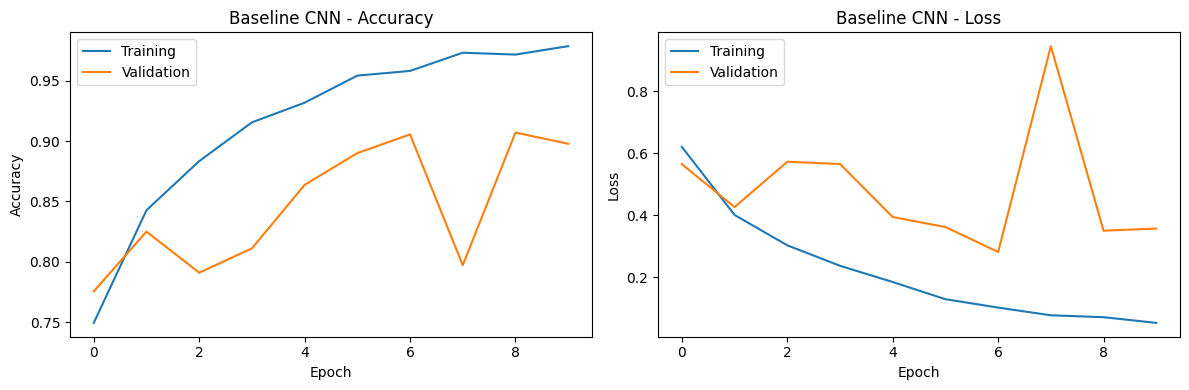

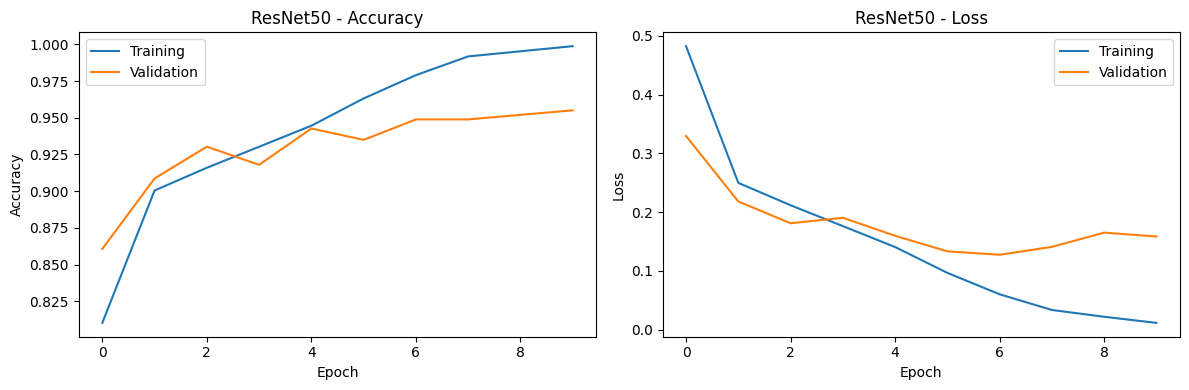

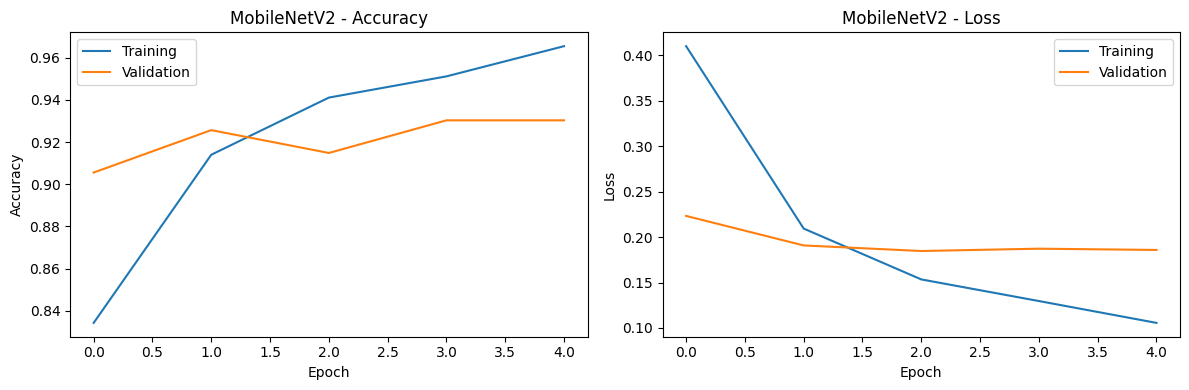

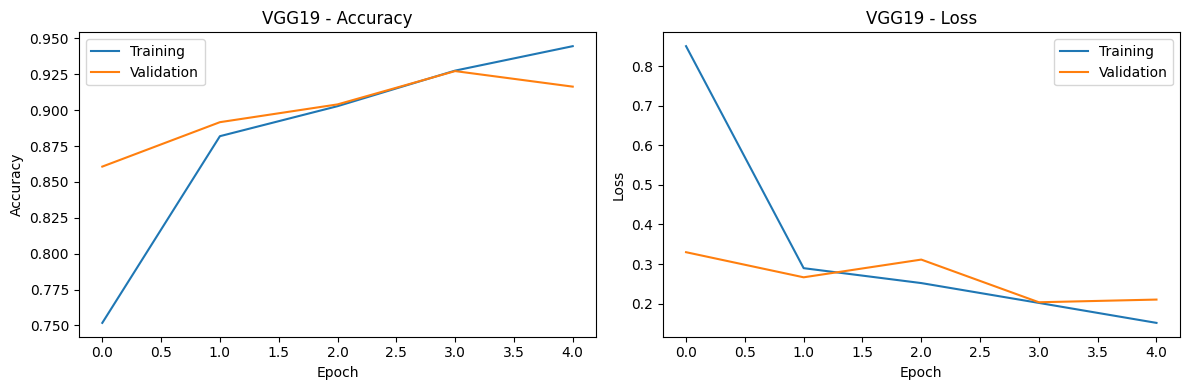

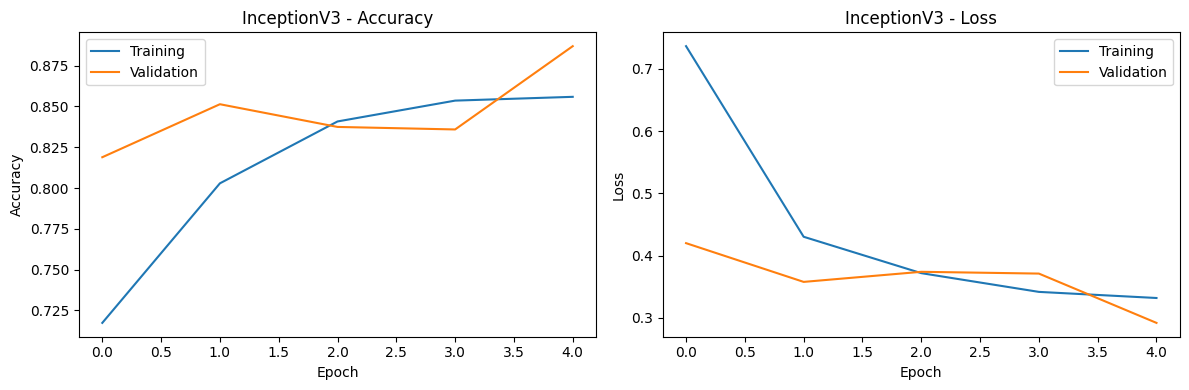

In [25]:
# Combine ResNet's initial training and fine-tuning history
resnet_curves = {
    key: resnet_history.history[key] + fine_tune_history.history[key]
    for key in ["accuracy", "val_accuracy", "loss", "val_loss"]
}

histories = {
    "Baseline CNN": baseline_history.history,
    "ResNet50": resnet_curves,
    "MobileNetV2": mobilenet_history.history,
    "VGG19": vgg_history.history,
    "InceptionV3": inception_history.history
}

# Plot accuracy and loss for each model
for name, history in histories.items():
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    for ax, metric in zip(axes, ["accuracy", "loss"]):
        ax.plot(history[metric], label="Training")
        ax.plot(history["val_" + metric], label="Validation")
        ax.set_title(f"{name} - {metric.title()}")
        ax.set_xlabel("Epoch")
        ax.set_ylabel(metric.title())
        ax.legend()

    plt.tight_layout()
    plt.show()

---

## 6. Augmentation

Re-train **at least one** of your models using **data augmentation** (e.g., flipping, rotation, zoom, cropping, contrast changes), and compare its performance with the same model trained without augmentation.

> **Tip:** Keras augmentation layers such as `layers.RandomFlip`, `layers.RandomRotation`, `layers.RandomZoom`, and `layers.RandomContrast` can be added at the start of a model. They only change images during training. Think about which augmentations make sense for chest X-rays.

In [26]:
# Define data augmentation
augmentation = keras.Sequential([
    layers.RandomRotation(0.03),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1)
])

# Create a fresh copy of the baseline CNN
augmented_baseline = keras.Sequential([
    Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    augmentation,
    keras.models.clone_model(baseline_model)
])

# Compile
augmented_baseline.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Train
augmented_history = augmented_baseline.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=32
)

# Compare performance
for name, model in [
    ("Original Baseline", baseline_model),
    ("Augmented Baseline", augmented_baseline)
]:
    loss, acc = model.evaluate(X_test, y_test, verbose=0)
    print(f"{name}: Accuracy = {acc:.2%}, Loss = {loss:.4f}")

Epoch 1/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 13s 72ms/step - accuracy: 0.5678 - loss: 0.8240 - val_accuracy: 0.7988 - val_loss: 0.5690
Epoch 2/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 4s 46ms/step - accuracy: 0.7343 - loss: 0.5692 - val_accuracy: 0.8142 - val_loss: 0.4969
Epoch 3/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 4s 45ms/step - accuracy: 0.7668 - loss: 0.5190 - val_accuracy: 0.8189 - val_loss: 0.4303
Epoch 4/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 4s 45ms/step - accuracy: 0.7723 - loss: 0.4969 - val_accuracy: 0.8282 - val_loss: 0.4045
Epoch 5/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 4s 53ms/step - accuracy: 0.7978 - loss: 0.4622 - val_accuracy: 0.8282 - val_loss: 0.3996
Epoch 6/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 4s 44ms/step - accuracy: 0.8273 - loss: 0.4055 - val_accuracy: 0.8452 - val_loss: 0.3812
Epoch 7/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 4s 44ms/step - accuracy: 0.8350 - loss: 0.3815 - val_accuracy: 0.8684 - val_loss: 0.3498
Epoch 8/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 4s 49ms/step - accuracy: 0.8563 - loss: 0.3426 - val_accuracy: 0.8916 - 

Describe the augmentations you used and why you chose them. How did they affect performance?

We used three data augmentation techniques:

- **Rotation:** Small rotations to account for differences in patient positioning.
- **Zoom:** Slight zoom adjustments to simulate different image scales.
- **Contrast:** Changes in contrast to simulate variations in X-ray quality.

These techniques were chosen to improve generalization and reduce overfitting without significantly altering the images. We avoid horizontal flipping because it can reverse the left and right sides of the chest.

**Results:**

| Metric | Original Baseline | Augmented Baseline |
|---|---:|---:|
| Test Accuracy | 91.70% | 88.72% |
| Test Loss | 0.3267 | 0.2736 |

Augmentation decreased test accuracy by **2.98 percentage points**,
but reduced test loss.

Overall, augmentation did not improve accuracy. However, the lower
loss suggests that the augmented model made less severe prediction
errors on average, despite making more incorrect classifications.

---

## 7. Interpretability and Insights

Conclude your project:

- **Which model performed best, and why?** Support your reasoning with performance metrics and training curves.
- **What is the practical utility of your best-performing model?**
  - Who would benefit from using this model?
  - In what types of real-world scenarios would your solution be useful?

**1. Which model performed best, and why?**

ResNet50 was the best-performing model, achieving **95.17% test
accuracy** and **0.1296 test loss**.

The other models achieved:
- VGG19: 93.56%
- MobileNetV2: 93.56%
- Baseline CNN: 91.70%
- InceptionV3: 86.25%

ResNet50 outperformed the baseline by **3.47 percentage points**.

ResNet50 likely performed better because its pretrained features
provided a strong starting point, while fine-tuning allowed it
to adapt to chest X-ray images.

Its high accuracy and low test loss suggest that transfer
learning was effective for this classification task.

**2. What is the practical utility of the best model?**

ResNet50 could help radiologists and healthcare professionals
identify COVID-19, viral pneumonia, and normal chest X-rays.

It could be useful in:
- Hospitals with limited radiology staff
- Emergency departments requiring faster screening
- Rural healthcare facilities with limited specialist access

However, despite its 95.17% test accuracy, the model is not
suitable for clinical diagnosis without further validation.

It should be used as a decision-support tool rather than
a replacement for medical professionals.